# 02 · Segmentação de clientes (agrupamento)

**Pergunta de negócio:** *que perfis de cliente a empresa tem, e como atender cada um?*

Hoje a empresa trata todos os clientes da mesma forma: o mesmo atendimento, a mesma divulgação, o mesmo
processo de orçamento. Se existirem grupos com comportamentos diferentes, cada um pode receber uma
estratégia própria de marketing, de preço e de atendimento.

## Por que agrupamento?

- **Não existe rótulo.** Ninguém anotou "este cliente é do tipo X". O objetivo é **descobrir** os grupos,
  não prever um rótulo conhecido. Por isso é um problema **não supervisionado**.
- Classificação e regressão precisariam de uma resposta certa para aprender, e ela não existe aqui.

## Por que K-Means?

| Algoritmo | Prós | Contras para este caso | Decisão |
|---|---|---|---|
| **K-Means** | Simples, rápido; cada grupo tem um "cliente médio" (centroide) fácil de explicar ao dono da empresa | Precisa escolher *k*; supõe grupos aproximadamente esféricos | ✅ **Escolhido** |
| Hierárquico (Ward) | Mostra a hierarquia em um dendrograma | Com 330 clientes o dendrograma fica ilegível; o resultado tende a ser parecido com o do K-Means | Usado só como conferência |
| DBSCAN | Encontra formas irregulares e outliers | Difícil de calibrar (`eps`); com poucas variáveis densas costuma juntar quase tudo em 1 grupo | Descartado |

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RAIZ = Path.cwd().parent
sys.path.insert(0, str(RAIZ / "scripts"))
import estilo_graficos as eg

eg.aplicar_estilo()
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", "{:,.2f}".format)
DIR_PROC = RAIZ / "dados" / "processed"

from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.preprocessing import StandardScaler

from preparar_dados import ler_processados

## 1. Preparação: escolha das variáveis

Cada cliente é descrito pelo seu **comportamento de compra**:

| Variável | O que mede | Transformação |
|---|---|---|
| `n_orcamentos` | Frequência: quantas vezes pediu orçamento | log (poucos clientes pedem muito; o log evita que eles dominem) |
| `ticket_medio` | Tamanho típico da obra (quantidade × preço de tabela, mediana) | log (valores de R$ 100 a R$ 20 mil) |
| `pct_decorativo` | % dos pedidos em sanca, moldura, gesso 3D, boiserie | – |
| `pct_gesso_liso` | % dos pedidos em gesso liso (acabamento simples de parede) | – |
| `pct_residencial` | % dos pedidos em imóvel residencial | – |

**Variáveis deixadas de fora, e por quê:**
- `pct_drywall`: as três porcentagens de tipo de serviço somam 100%. Com duas delas, a terceira é redundante e daria peso dobrado a esse aspecto.
- `taxa_conversao` e `desconto_medio`: são **resultados** da negociação, não perfil do cliente. Além disso, a taxa de fechamento será o alvo do notebook 03. Usá-la aqui faria o segmento "vazar" a resposta para aquele modelo.
- Cidade e origem do contato: são categóricas, e o K-Means trabalha com distâncias numéricas. Elas ficam para **interpretar** os grupos depois. Se os grupos se diferenciarem por origem sem que a origem tenha sido usada, isso é uma descoberta.

In [2]:
clientes = ler_processados()["clientes"]

# as 3 porcentagens de tipo de serviço somam 1 -> uma delas é redundante
soma = clientes[["pct_drywall", "pct_decorativo", "pct_gesso_liso"]].sum(axis=1)
print(f"pct_drywall + pct_decorativo + pct_gesso_liso: mín {soma.min():.2f}, máx {soma.max():.2f}")

# segurança: cliente cujo único orçamento teve quantidade inválida fica sem ticket
clientes["ticket_medio"] = clientes["ticket_medio"].fillna(clientes["ticket_medio"].median())

clientes["log_orcamentos"] = np.log1p(clientes["n_orcamentos"])
clientes["log_ticket"] = np.log1p(clientes["ticket_medio"])
VARIAVEIS = ["log_orcamentos", "log_ticket", "pct_decorativo", "pct_gesso_liso", "pct_residencial"]
clientes[VARIAVEIS].describe().T

pct_drywall + pct_decorativo + pct_gesso_liso: mín 1.00, máx 1.00


,count,mean,std,min,25%,50%,75%,max
log_orcamentos,330.00,1.64,0.48,0.69,1.39,1.61,1.95,3.91
log_ticket,330.00,7.23,1.15,4.07,6.40,7.22,8.16,9.89
pct_decorativo,330.00,0.34,0.34,0.00,0.00,0.25,0.50,1.00
pct_gesso_liso,330.00,0.24,0.30,0.00,0.00,0.11,0.50,1.00
pct_residencial,330.00,0.63,0.48,0.00,0.00,1.00,1.00,1.00


**Padronização.** O K-Means mede distância. Sem padronizar, o `log_ticket` (escala ~5 a 10) pesaria mais que
as porcentagens (escala 0 a 1) só por causa da unidade de medida. O `StandardScaler` coloca todas as
variáveis com média 0 e desvio 1.

In [3]:
X = StandardScaler().fit_transform(clientes[VARIAVEIS])
X.shape

(330, 5)

## 2. Quantos grupos? (*k*)

Dois critérios complementares, testando *k* de 2 a 8:
- **Cotovelo (inércia):** a soma das distâncias até o centro do grupo. Ela sempre cai com mais grupos; procura-se o ponto em que a queda perde força.
- **Silhueta:** de −1 a 1, mede quanto cada cliente está mais perto do próprio grupo do que do vizinho. Acima de 0,25 indica estrutura razoável; acima de 0,5, estrutura forte.

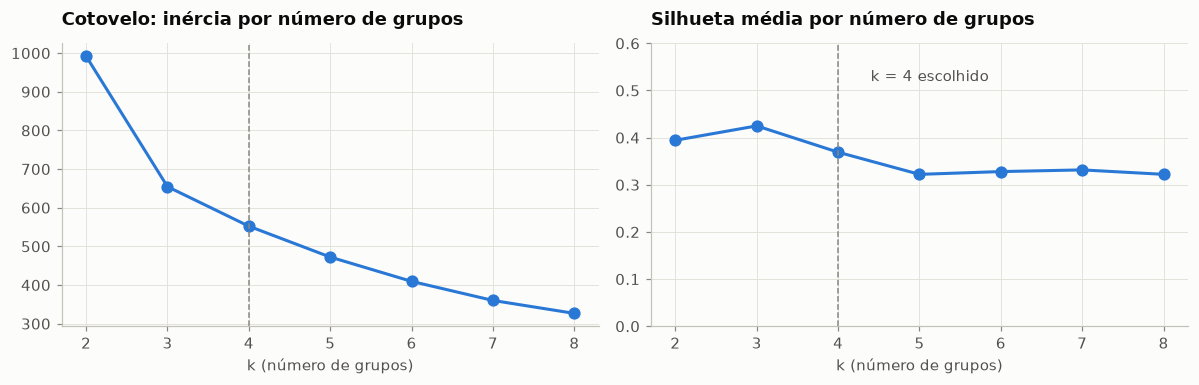

k,2,3,4,5,6,7,8
inércia,991.96,654.42,552.19,472.31,409.42,360.06,326.60
silhueta,0.39,0.42,0.37,0.32,0.33,0.33,0.32


In [4]:
ks = range(2, 9)
inercia, silhueta = [], []
for k in ks:
    modelo = KMeans(n_clusters=k, n_init=20, random_state=42).fit(X)
    inercia.append(modelo.inertia_)
    silhueta.append(silhouette_score(X, modelo.labels_))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].plot(list(ks), inercia, marker="o", color=eg.CORES[0])
axes[0].set_title("Cotovelo: inércia por número de grupos")
axes[0].set_xlabel("k (número de grupos)")
axes[1].plot(list(ks), silhueta, marker="o", color=eg.CORES[0])
axes[1].set_title("Silhueta média por número de grupos")
axes[1].set_xlabel("k (número de grupos)")
axes[1].set_ylim(0, 0.6)
for ax in axes:
    ax.axvline(4, color=eg.TINTA_SUAVE, linestyle="--", linewidth=1)
axes[1].annotate("k = 4 escolhido", xy=(4, silhueta[2]), xytext=(4.4, 0.52), color=eg.TINTA_SECUNDARIA)
plt.tight_layout()
plt.show()

pd.DataFrame({"k": list(ks), "inércia": inercia, "silhueta": silhueta}).set_index("k").round(3).T

**Escolha: k = 4.**
- A silhueta é máxima com k = 3 (~0,42), mas k = 4 fica próximo (~0,37), bem acima de 0,25. A partir de 5 ela cai de forma contínua.
- No cotovelo, a queda de inércia perde força a partir de k = 4.
- **Critério de negócio:** com k = 3, construtoras e pequenos comércios ficam no mesmo grupo. São clientes com
  frequência, ticket e forma de chegada muito diferentes (veja a seção 4), que pedem estratégias diferentes.
  Um grupo a mais que gera uma ação diferente vale a pequena perda de silhueta.

## 3. Treino do modelo final e visualização

In [5]:
kmeans = KMeans(n_clusters=4, n_init=20, random_state=42).fit(X)
clientes["grupo"] = kmeans.labels_
print(f"Silhueta final: {silhouette_score(X, kmeans.labels_):.3f}")

# Dar nome aos grupos a partir do perfil médio (regra explícita, não "no olho")
media = clientes.groupby("grupo")[["n_orcamentos", "pct_decorativo", "pct_residencial"]].mean()
nao_residencial = media[media["pct_residencial"] < 0.5]
residencial = media[media["pct_residencial"] >= 0.5]
assert len(nao_residencial) == 2 and len(residencial) == 2
nomes = {
    nao_residencial["n_orcamentos"].idxmax(): "Construtoras e obras grandes",
    nao_residencial["n_orcamentos"].idxmin(): "Pequeno comércio",
    residencial["pct_decorativo"].idxmax(): "Residencial alto padrão",
    residencial["pct_decorativo"].idxmin(): "Residencial econômico",
}
SEGMENTOS = ["Construtoras e obras grandes", "Pequeno comércio", "Residencial alto padrão", "Residencial econômico"]
clientes["segmento"] = pd.Categorical(clientes["grupo"].map(nomes), categories=SEGMENTOS, ordered=True)
clientes["segmento"].value_counts(sort=False).to_frame("clientes")

Silhueta final: 0.369


,clientes
segmento,
Construtoras e obras grandes,36
Pequeno comércio,90
Residencial alto padrão,96
Residencial econômico,108


Para enxergar 5 variáveis em 2 dimensões, usa-se **PCA** (análise de componentes principais). Ela só serve
para a visualização: o agrupamento foi feito nas 5 variáveis originais.

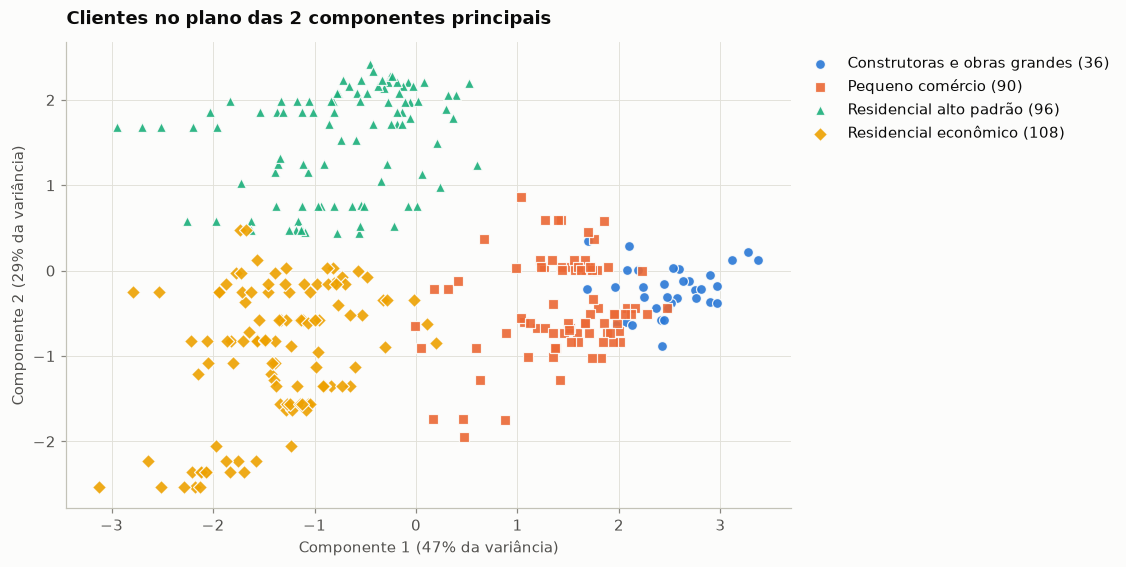

In [6]:
pca = PCA(n_components=2, random_state=42)
coords = pca.fit_transform(X)

fig, ax = plt.subplots(figsize=(8.5, 5.5))
for i, seg in enumerate(SEGMENTOS):
    m = (clientes["segmento"] == seg).values
    ax.scatter(coords[m, 0], coords[m, 1], s=42, color=eg.CORES[i], marker=eg.MARCADORES[i],
               edgecolor=eg.FUNDO, linewidth=0.8, alpha=0.9, label=f"{seg} ({m.sum()})")
ax.set_title("Clientes no plano das 2 componentes principais")
ax.set_xlabel(f"Componente 1 ({pca.explained_variance_ratio_[0]:.0%} da variância)")
ax.set_ylabel(f"Componente 2 ({pca.explained_variance_ratio_[1]:.0%} da variância)")
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.show()

## 4. Interpretação: quem é cada grupo?

In [7]:
perfil = clientes.groupby("segmento", observed=True).agg(
    clientes=("id_cliente", "size"),
    orcamentos_por_cliente=("n_orcamentos", "mean"),
    ticket_mediano=("ticket_medio", "median"),
    pct_drywall=("pct_drywall", "mean"),
    pct_decorativo=("pct_decorativo", "mean"),
    pct_gesso_liso=("pct_gesso_liso", "mean"),
    pct_residencial=("pct_residencial", "mean"),
    taxa_fechamento=("taxa_conversao", "mean"),
    desconto_medio=("desconto_medio", "mean"),
    faturamento=("faturamento_total", "sum"),
)
perfil["% clientes"] = perfil["clientes"] / perfil["clientes"].sum() * 100
perfil["% faturamento"] = perfil["faturamento"] / perfil["faturamento"].sum() * 100
perfil["faturamento_por_cliente"] = perfil["faturamento"] / perfil["clientes"]
perfil.T

segmento,Construtoras e obras grandes,Pequeno comércio,Residencial alto padrão,Residencial econômico
clientes,36.00,90.00,96.00,108.00
orcamentos_por_cliente,11.83,3.87,4.70,3.47
ticket_mediano,"6,067.18","3,491.36","1,018.91",614.65
pct_drywall,0.79,0.78,0.17,0.22
pct_decorativo,0.09,0.14,0.78,0.19
pct_gesso_liso,0.13,0.09,0.04,0.59
pct_residencial,0.00,0.03,1.00,1.00
taxa_fechamento,0.66,0.44,0.62,0.53
desconto_medio,4.16,2.66,1.92,4.38
faturamento,"1,563,624.89","558,990.53","477,865.18","106,250.77"


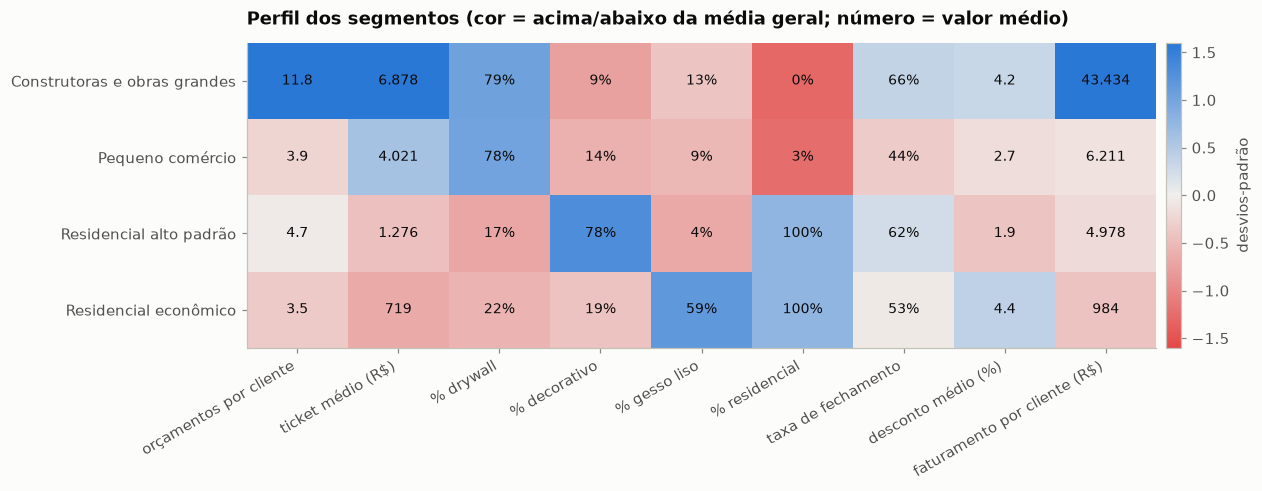

In [8]:
# Mapa de calor: cada característica comparada com a média geral (desvios-padrão)
caracteristicas = {
    "orçamentos por cliente": "n_orcamentos", "ticket médio (R$)": "ticket_medio",
    "% drywall": "pct_drywall", "% decorativo": "pct_decorativo", "% gesso liso": "pct_gesso_liso",
    "% residencial": "pct_residencial", "taxa de fechamento": "taxa_conversao",
    "desconto médio (%)": "desconto_medio", "faturamento por cliente (R$)": "faturamento_total",
}
medias = clientes.groupby("segmento", observed=True)[list(caracteristicas.values())].mean()
z = (medias - clientes[list(caracteristicas.values())].mean()) / clientes[list(caracteristicas.values())].std()

fig, ax = plt.subplots(figsize=(11, 3.6))
im = ax.imshow(z.values, cmap=eg.DIVERGENTE, vmin=-1.6, vmax=1.6, aspect="auto")
ax.set_xticks(range(len(caracteristicas)), list(caracteristicas), rotation=30, ha="right")
ax.set_yticks(range(len(z)), z.index)
ax.grid(False)
for i in range(z.shape[0]):
    for j, col in enumerate(caracteristicas.values()):
        v = medias.iloc[i, j]
        texto = f"{v:.0%}" if col.startswith(("pct", "taxa")) else (f"{v:,.0f}" if v >= 100 else f"{v:.1f}")
        ax.text(j, i, texto.replace(",", "."), ha="center", va="center", fontsize=9, color=eg.TINTA)
ax.set_title("Perfil dos segmentos (cor = acima/abaixo da média geral; número = valor médio)")
fig.colorbar(im, ax=ax, fraction=0.02, pad=0.01, label="desvios-padrão")
plt.show()

**A origem do contato não foi usada no agrupamento.** Mesmo assim, cada segmento chega à empresa por
canais bem diferentes. Isso é uma descoberta do modelo e tem aplicação direta no marketing:

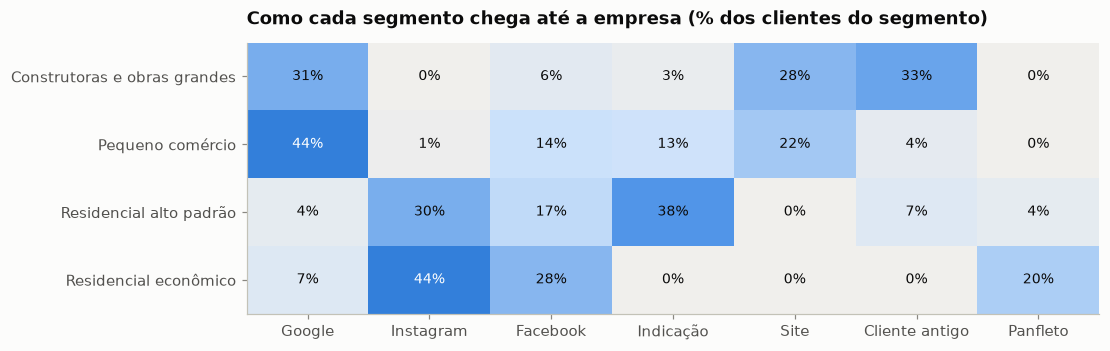

In [9]:
origem = pd.crosstab(clientes["segmento"], clientes["origem_contato"], normalize="index")
origem = origem[origem.sum().sort_values(ascending=False).index]

fig, ax = plt.subplots(figsize=(10, 3.2))
ax.imshow(origem.values, cmap=eg.SEQUENCIAL, vmin=0, vmax=0.7, aspect="auto")
ax.set_xticks(range(origem.shape[1]), origem.columns)
ax.set_yticks(range(origem.shape[0]), origem.index)
ax.grid(False)
for i in range(origem.shape[0]):
    for j in range(origem.shape[1]):
        v = origem.iloc[i, j]
        ax.text(j, i, f"{v:.0%}", ha="center", va="center", fontsize=9,
                color="white" if v > 0.4 else eg.TINTA)
ax.set_title("Como cada segmento chega até a empresa (% dos clientes do segmento)")
plt.show()

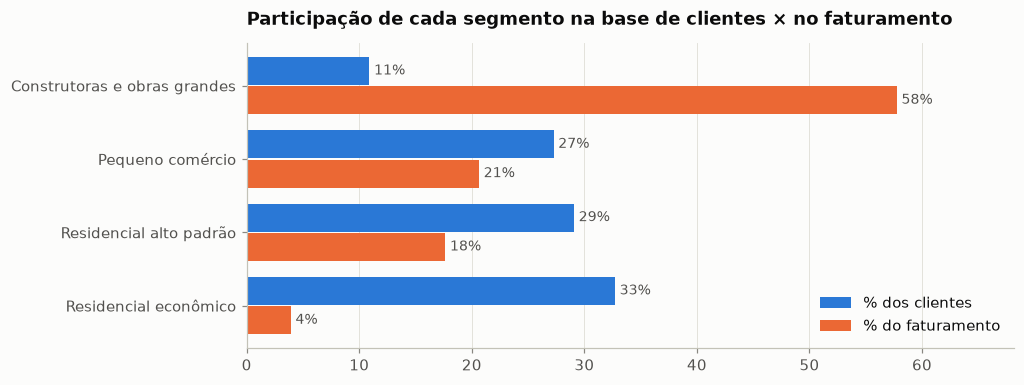

In [10]:
fig, ax = plt.subplots(figsize=(9, 3.6))
y = np.arange(len(SEGMENTOS))
b1 = ax.barh(y - 0.2, perfil["% clientes"], height=0.38, color=eg.CORES[0], label="% dos clientes")
b2 = ax.barh(y + 0.2, perfil["% faturamento"], height=0.38, color=eg.CORES[1], label="% do faturamento")
eg.rotular_barras(ax, b1, "{:.0f}%")
eg.rotular_barras(ax, b2, "{:.0f}%")
ax.set_yticks(y, SEGMENTOS)
ax.invert_yaxis()
ax.set_xlim(0, max(perfil["% clientes"].max(), perfil["% faturamento"].max()) * 1.18)
ax.grid(axis="y", visible=False)
ax.set_title("Participação de cada segmento na base de clientes × no faturamento")
ax.legend(loc="lower right")
plt.show()

### Leitura dos segmentos

| Segmento | Quem é | Números que definem o grupo |
|---|---|---|
| 🏗️ **Construtoras e obras grandes** (36 clientes, 11%) | Empresas com obra comercial/industrial, que voltam sempre | ~12 orçamentos por cliente (3× os demais), ticket mediano ~R$ 6 mil, 79% drywall. **58% do faturamento** com 11% dos clientes (~R$ 43 mil por cliente) |
| 🏪 **Pequeno comércio** (90, 27%) | Lojas e escritórios: forro e divisória drywall | Mesmo mix de serviços das construtoras, mas obras menores (~R$ 3,5 mil) e poucos pedidos (~4). **Menor taxa de fechamento: 44%** |
| ✨ **Residencial alto padrão** (96, 29%) | Casas com acabamento decorativo | 78% dos pedidos em sanca, moldura, gesso 3D e boiserie; **menor desconto** (1,9%) e boa taxa de fechamento (62%) |
| 🏠 **Residencial econômico** (108, 33%) | Reforma simples de casa | 59% gesso liso, menor ticket (~R$ 600), **maior desconto** (4,4%). É o maior grupo, mas responde por só **4% do faturamento** |

## 5. Conferências de robustez

**a) Outro algoritmo chega aos mesmos grupos?** O agrupamento hierárquico (Ward) usa uma lógica diferente
(junta clientes de baixo para cima). Se ele concordar com o K-Means, os grupos são estrutura real dos dados
e não um artefato do algoritmo.

In [11]:
hierarquico = AgglomerativeClustering(n_clusters=4, linkage="ward").fit_predict(X)
print(f"Concordância K-Means × Hierárquico (ARI): {adjusted_rand_score(kmeans.labels_, hierarquico):.2f}")

Concordância K-Means × Hierárquico (ARI): 0.53


**b) Prova real com o gabarito do simulador.** O simulador sorteia cada cliente a partir de 4 perfis
"escondidos", que o modelo nunca viu. O ARI (*Adjusted Rand Index*) mede a concordância entre
agrupamentos: 0 equivale a um sorteio, 1 a uma concordância perfeita.

In [12]:
gabarito = pd.read_csv(RAIZ / "dados" / "raw" / "gabarito_perfis.csv")
conferencia = clientes.merge(gabarito[["id_cliente", "perfil_real"]], on="id_cliente")
ari = adjusted_rand_score(conferencia["perfil_real"], conferencia["segmento"])
print(f"ARI segmento encontrado × perfil real: {ari:.2f}")
pd.crosstab(conferencia["segmento"], conferencia["perfil_real"])

ARI segmento encontrado × perfil real: 0.62


perfil_real,alto_padrao,construtora,pequeno_comercio,residencial_economico
segmento,,,,
Construtoras e obras grandes,0,28,8,0
Pequeno comércio,0,7,80,3
Residencial alto padrão,58,0,0,38
Residencial econômico,0,0,0,108


**Leitura das conferências:**
- **ARI = 0,62 contra o gabarito:** concordância boa, bem acima do acaso (0). O modelo separou com clareza os
  clientes **residenciais** dos **comerciais/industriais**, e dentro de cada lado separou os perfis com
  poucos erros.
- **Onde ele "erra", e por quê:** 38 clientes sorteados como *econômicos* caíram em *alto padrão*. Isso
  acontece porque eles pediram justamente sanca e moldura, e pelo comportamento de compra parecem alto padrão.
  Do ponto de vista do negócio, tratar esses clientes como alto padrão é defensável: o que importa é o que o cliente compra, não o rótulo.
  Entre construtoras e pequeno comércio há 15 trocas: construtoras pequenas e comércios grandes ficam na fronteira.
- **K-Means × Hierárquico (ARI = 0,53):** concordância moderada. A divisão residencial × comercial é estável
  nos dois métodos, e as diferenças ficam nas mesmas fronteiras citadas acima. Os 4 segmentos devem ser lidos como
  **perfis típicos**, não como caixas rígidas.

In [13]:
clientes[["id_cliente", "segmento"]].to_csv(DIR_PROC / "segmentos.csv", index=False)

metricas = {
    "k": 4,
    "silhueta": round(float(silhouette_score(X, kmeans.labels_)), 3),
    "ari_hierarquico": round(float(adjusted_rand_score(kmeans.labels_, hierarquico)), 3),
    "ari_gabarito": round(float(ari), 3),
    "perfil": perfil[["clientes", "% clientes", "% faturamento", "faturamento_por_cliente",
                      "taxa_fechamento", "ticket_mediano"]].round(2).reset_index().to_dict("records"),
    "origem_principal": {seg: origem.loc[seg].idxmax() for seg in SEGMENTOS},
}
(DIR_PROC / "metricas_segmentacao.json").write_text(json.dumps(metricas, ensure_ascii=False, indent=2, default=str))
print("Segmentos salvos em dados/processed/segmentos.csv")

Segmentos salvos em dados/processed/segmentos.csv


## Insights e recomendações

1. **A receita é muito concentrada.** 11% dos clientes (construtoras) geram 58% do faturamento. Perder um deles custa
   o mesmo que perder ~44 clientes residenciais econômicos. **Ação:** atendimento dedicado (um responsável fixo,
   orçamento prioritário) e acompanhamento pós-obra. Um terço deles já chega como "cliente antigo", ou seja, a recompra é o canal principal desse segmento.
2. **Cada canal de marketing traz um tipo de cliente diferente**, e isso apareceu sem que a origem fosse usada no modelo:
   - **Google e site** trazem construtoras e comércio → investir em **anúncios de busca e SEO local** com termos como "drywall comercial" e "divisória para escritório".
   - **Indicação e Instagram** trazem o alto padrão → **portfólio visual no Instagram** (sanca, gesso 3D, boiserie) e um **programa de indicação**.
   - **Facebook e panfleto** trazem quase só o residencial econômico, o de menor retorno → é onde cortar verba primeiro.
3. **O residencial econômico é volume sem margem:** 33% dos clientes, 4% do faturamento e o maior desconto médio.
   **Ação:** criar **pacotes de preço fechado** para gesso liso (orçamento rápido pelo WhatsApp, sem visita) e limitar o desconto.
4. **O pequeno comércio fecha pouco (44%).** O notebook 03 investiga se isso é do segmento em si ou do processo de
   atendimento (demora para responder, falta de visita técnica).

➡️ O segmento de cada cliente vira **variável de entrada** nos notebooks
[03 · Fechamento de orçamentos](03_fechamento_orcamentos.ipynb) e [04 · Estimativa de preço](04_estimativa_preco.ipynb).